In [2]:
import os
import json
import numpy as np
import pandas as pd
import scipy.io
import anndata as ad
from scipy.sparse import lil_matrix, issparse
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA, NMF
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from umap import UMAP

import torch
import torch.nn as nn
import torch.nn.functional as F
import pyliger

In [16]:
%matplotlib inline

In [4]:
def as_dense(x):
    return x.toarray() if issparse(x) else np.asarray(x)

def jaccard(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    denom = np.logical_or(a, b).sum()
    return 0.0 if denom == 0 else np.logical_and(a, b).sum() / denom

def top_support_mask(vec, frac=0.05):
    vec = np.abs(np.asarray(vec).ravel())
    k = max(1, int(np.ceil(frac * vec.size)))
    mask = np.zeros(vec.size, dtype=bool)
    mask[np.argpartition(vec, -k)[-k:]] = True
    return mask

def edge_overlap_metrics(A_pred, A_ref, frac=0.05):
    pred = top_support_mask(A_pred, frac=frac)
    ref = top_support_mask(A_ref, frac=frac)
    tp = np.logical_and(pred, ref).sum()
    fp = pred.sum() - tp
    fn = ref.sum() - tp
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    jac = tp / (pred.sum() + ref.sum() - tp + 1e-8)
    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "jaccard": float(jac),
        "tp": int(tp),
        "pred_edges": int(pred.sum()),
        "ref_edges": int(ref.sum()),
    }

def mean_axis_jaccard(A_pred, A_ref, axis=0, frac=0.1):
    scores = []
    if axis == 0:  # per TF column
        for j in range(A_ref.shape[1]):
            p = top_support_mask(A_pred[:, j], frac=frac)
            r = top_support_mask(A_ref[:, j], frac=frac)
            scores.append(jaccard(p, r))
    else:  # per gene row
        for i in range(A_ref.shape[0]):
            p = top_support_mask(A_pred[i, :], frac=frac)
            r = top_support_mask(A_ref[i, :], frac=frac)
            scores.append(jaccard(p, r))
    return float(np.mean(scores)) if scores else 0.0

def module_sets_from_nmf(W, H, top_genes=25, top_tfs=15):
    # W: genes x r, H: r x tfs
    modules = []
    for k in range(W.shape[1]):
        g_idx = np.argsort(-W[:, k])[:top_genes]
        t_idx = np.argsort(-H[k, :])[:top_tfs]
        modules.append((set(g_idx.tolist()), set(t_idx.tolist())))
    return modules

def module_similarity(m1, m2):
    g1, t1 = m1
    g2, t2 = m2
    return 0.5 * jaccard(g1, g2) + 0.5 * jaccard(t1, t2)

def match_module_sets(ref_modules, cur_modules):
    S = np.array([[module_similarity(r, c) for c in cur_modules] for r in ref_modules], dtype=float)
    row_ind, col_ind = linear_sum_assignment(-S)
    matched = S[row_ind, col_ind]
    return {
        "mean_conservation": float(np.mean(matched)),
        "std_conservation": float(np.std(matched)),
        "matched_scores": matched,
        "similarity_matrix": S,
    }

def pseudotime_arrow_agreement(X_space, V_pred, pseudotime, k=30):
    """
    For each cell, find the nearest neighbor with slightly larger pseudotime
    among local neighbors, and compare that arrow with predicted velocity.
    Returns mean cosine agreement and fraction positive.
    """
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(X_space))).fit(X_space)
    idx = nn.kneighbors(X_space, return_distance=False)[:, 1:]

    arrows = np.zeros_like(X_space, dtype=float)
    valid = np.zeros(len(X_space), dtype=bool)

    for i in range(len(X_space)):
        nbrs = idx[i]
        later = nbrs[pseudotime[nbrs] > pseudotime[i]]
        if later.size == 0:
            continue
        j = later[np.argmin(pseudotime[later] - pseudotime[i])]
        arrows[i] = X_space[j] - X_space[i]
        valid[i] = True

    if valid.sum() == 0:
        return {"mean_cosine": np.nan, "fraction_positive": np.nan, "n_valid": 0}

    Vn = normalize(V_pred[valid], norm="l2", axis=1)
    An = normalize(arrows[valid], norm="l2", axis=1)
    cos = np.sum(Vn * An, axis=1)

    return {
        "mean_cosine": float(np.mean(cos)),
        "fraction_positive": float(np.mean(cos > 0)),
        "n_valid": int(valid.sum()),
        "cosines": cos,
    }

## Step 1: Load RNA

In [5]:
BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
os.makedirs("uv_leading_metrics_improved", exist_ok=True)

rna_adata = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
gene_names_all = np.array(rna_adata.var_names.astype(str))
gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
X_full = as_dense(rna_adata.X).astype(np.float32)

peak_tf = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()
motif_tf_names = open(f"{BASE}/tf_names.txt").read().strip().split()
motif_tf_to_idx = {t: i for i, t in enumerate(motif_tf_names)}

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")
peaks = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()
peak_to_idx = {p: i for i, p in enumerate(peaks)}

genes_in_peaks = set(peak_gene["gene"].astype(str).unique())
A_genes = np.array([g for g in gene_names_all if g in genes_in_peaks], dtype=str)

# IMPORTANT: TFs must exist as genes in the RNA matrix for X_TF
A_tfs = np.array([t for t in motif_tf_names if t in gene_to_idx_full], dtype=str)

print(f"A_genes: {len(A_genes)}, A_tfs: {len(A_tfs)}")

gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)

X = X_full[:, gene_idx]      # cells x genes
X_TF = X_full[:, tf_idx]     # cells x TFs
sub_g2i = {g: i for i, g in enumerate(A_genes)}

A_genes: 11483, A_tfs: 277


## Build M

In [6]:
P = len(peaks)
G = len(A_genes)

peak_gene_mat = lil_matrix((P, G), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = str(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx and g in sub_g2i:
        peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1.0
peak_gene_mat = peak_gene_mat.tocsr()

M_full = (peak_gene_mat.T @ peak_tf)
M_full = (M_full > 0).astype(np.float32)

# align M columns to the TFs actually present in RNA
A_tfs = np.array([t for t in A_tfs if t in motif_tf_to_idx], dtype=str)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)
tf_col = np.array([motif_tf_to_idx[t] for t in A_tfs], dtype=int)

X_TF = X_full[:, tf_idx]  # refresh after final TF filtering
M = M_full[:, tf_col].toarray().astype(np.float32)

assert M.shape == (len(A_genes), len(A_tfs))

## ATAC Prior

In [7]:
# ============================================================
# STEP 3 (REPLACE): ATAC gene activity and gene accessibility
# ============================================================

print("Loading ATAC raw matrix...")
atac_raw = scipy.io.mmread(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz").tocsr()
atac_X = atac_raw.T.astype(np.float32)   # cells x peaks

peaks_atac = pd.read_csv(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.peaks.txt.gz", sep="\t")
peak_names = peaks_atac["Feature"].str.replace("_", ":", n=1).str.replace("_", "-", n=1).tolist()
peak_to_idx_atac = {p: i for i, p in enumerate(peak_names)}

def fix_peak(p):
    return str(p).replace("-", ":", 1)

P2 = len(peak_names)
G2 = len(A_genes)

peak_gene_mat_atac = lil_matrix((P2, G2), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = fix_peak(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx_atac and g in sub_g2i:
        peak_gene_mat_atac[peak_to_idx_atac[p], sub_g2i[g]] = 1.0
peak_gene_mat_atac = peak_gene_mat_atac.tocsr()

gene_activity = atac_X @ peak_gene_mat_atac   # cells x genes
gene_activity = normalize(gene_activity, norm="l1", axis=1)
gene_activity = as_dense(gene_activity).astype(np.float32)
gene_activity = np.log1p(gene_activity)

# IMPORTANT: do NOT row-align unpaired ATAC to RNA unless the data are truly paired.
# Use all ATAC cells for global priors and latent geometry.
gene_access = gene_activity.mean(axis=0)
gene_access = (gene_access - gene_access.min()) / (gene_access.max() - gene_access.min() + 1e-8)
gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

print(f"ATAC gene_activity shape: {gene_activity.shape}")
print(f"gene_access shape: {gene_access.shape}")

Loading ATAC raw matrix...
ATAC gene_activity shape: (18489, 11483)
gene_access shape: (11483,)


## Pre-compute some vectors

In [12]:
from scipy.stats import zscore

# ============================================================
# NEW STEP 4: Decipher-Constrained Future Projection
# ============================================================
from sklearn.neighbors import NearestNeighbors
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler
import numpy as np
import torch

# Ensure we have the device and tensors ready
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_t = torch.tensor(X, dtype=torch.float32, device=device)

# --------------------------------------------------
# 1. Build per-ATAC-cell TF accessibility score
# --------------------------------------------------
print("Step 4.1: Computing per-ATAC-cell TF accessibility...")

# Align Step 3 ATAC peaks to Step 1 Motif peaks
# Step 1 peaks used '-', Step 3 peak_names used ':'
# We map them to ensure we subset peak_tf correctly
peak_to_idx_motif = {p: i for i, p in enumerate(peaks)} 
valid_atac_indices = []
valid_motif_indices = []

for j, p_atac in enumerate(peak_names):
    # Reverse the 'fix_peak' logic to match Step 1 format
    p_orig = p_atac.replace(":", "-", 1)
    if p_orig in peak_to_idx_motif:
        valid_atac_indices.append(j)
        valid_motif_indices.append(peak_to_idx_motif[p_orig])

# subset matrices for TF activity calculation
# peak_tf is (Peaks_Total x TFs_Total), tf_col selects TFs present in RNA
atac_X_sub = atac_X[:, np.array(valid_atac_indices)]
peak_tf_sub = peak_tf[np.array(valid_motif_indices)][:, tf_col]

# Cells x TFs
TF_access_atac = as_dense(atac_X_sub @ peak_tf_sub).astype(np.float32)
TF_access_atac = np.log1p(TF_access_atac / (TF_access_atac.sum(axis=1, keepdims=True) + 1e-8) * 1e4)

# --------------------------------------------------
# 2. Transfer ATAC TF scores to RNA cells
# --------------------------------------------------
print("Step 4.2: Transferring ATAC to RNA using Decipher-guided kNN...")

# Reuse gene_activity from Step 3 (already log-normalized cells x genes)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
atac_scaled = scaler.transform(gene_activity)

# kNN Transfer
k_transfer = 20
nn_transfer = NearestNeighbors(n_neighbors=k_transfer, metric='cosine', n_jobs=-1).fit(atac_scaled)
dists, indices = nn_transfer.kneighbors(X_scaled)

# Weights
sigmas = np.median(dists, axis=1, keepdims=True) + 1e-8
weights = np.exp(-(dists**2) / (2 * sigmas**2))
weights /= (weights.sum(axis=1, keepdims=True) + 1e-8)

# Transfer TF accessibility to RNA cells: (N, k) * (N, k, TFs) -> (N, TFs)
TF_access_rna = np.sum(weights[:, :, np.newaxis] * TF_access_atac[indices], axis=1)

# Load Decipher space
decipher_data = np.load("decipher_outputs/decipher_embeddings.npz")
Z_dec = decipher_data["z"].astype(np.float32)   # (N, 10)
V_vis = decipher_data["v"].astype(np.float32)   # (N, 2)
N     = Z_dec.shape[0]
ps    = rna_adata.obs["facs_pseudotime"].values.astype(np.float32)

# Normalize pseudotime to [0,1] just in case
ps = (ps - ps.min()) / (ps.max() - ps.min() + 1e-8)

X_rna_z  = zscore(X,    axis=0).astype(np.float32)   # (N, G)
X_TF_arr = X_TF.astype(np.float32)                    # (N, T)

k_vis = 20
nn_vis = NearestNeighbors(n_neighbors=k_vis + 1).fit(V_vis)
dists_vis, idx_vis = nn_vis.kneighbors(V_vis)
idx_vis   = idx_vis[:, 1:]    # (N, k_vis)
dists_vis = dists_vis[:, 1:]

# Also build kNN in Z (for model training / consistency loss)
k_nn = 20
nn_z = NearestNeighbors(n_neighbors=k_nn + 1, metric='euclidean').fit(Z_dec)
dists_z, idx_z = nn_z.kneighbors(Z_dec)
idx_z   = idx_z[:, 1:]
dists_z = dists_z[:, 1:]

# Compute ATAC-RNA discrepancy magnitude per cell (used as weight only)
X_atac_pred  = TF_access_rna @ M.T                   # (N, G)
X_atac_z     = zscore(X_atac_pred, axis=0).astype(np.float32)
atac_rna_mag = np.linalg.norm(X_atac_z - X_rna_z, axis=1)  # (N,)
atac_rna_mag = (atac_rna_mag - atac_rna_mag.min()) / (atac_rna_mag.max() - atac_rna_mag.min() + 1e-8)

# Build ground truth 2D velocity and transition weights
V_gt_2d     = np.zeros((N, 2), dtype=np.float32)
P_trans     = np.zeros((N, k_vis), dtype=np.float32)   # transition probs
conf_scores = np.zeros(N, dtype=np.float32)

Step 4.1: Computing per-ATAC-cell TF accessibility...
Step 4.2: Transferring ATAC to RNA using Decipher-guided kNN...


In [68]:
def plot_velocity_field(X, V, color=None, title="Velocity Field",
                        grid_size=30, scale=20, width=0.002,
                        force_uniform_length=True):
    """
    X: (N, 2) coordinates
    V: (N, 2) velocity vectors
    grid_size: number of grid cells per axis
    scale: passed directly to quiver (higher = smaller arrows)
             Works the same as your old working code.
    """
    fig, ax = plt.subplots(figsize=(12, 8))

    # 1. Filter NaN/Inf
    mask = np.isfinite(V).all(axis=1) & np.isfinite(X).all(axis=1)
    X_f, V_f = X[mask], V[mask]
    color_f = color[mask] if (color is not None and not isinstance(color, str)) else color

    # 2. Trim spatial outliers PER AXIS using IQR clipping
    #    This is what fixes the PCA collapse — outlier cells were
    #    making the axis range ~10x too large, so arrows looked microscopic
    for dim in range(X_f.shape[1]):
        q1, q99 = np.percentile(X_f[:, dim], [1, 99])
        inlier = (X_f[:, dim] >= q1) & (X_f[:, dim] <= q99)
        X_f, V_f = X_f[inlier], V_f[inlier]
        if color_f is not None and not isinstance(color_f, str):
            color_f = color_f[inlier]

    # 3. Background scatter (FULL data, not trimmed — just hide outliers from arrows)
    sc = ax.scatter(X_f[:, 0], X_f[:, 1],
                    c=color_f if color_f is not None else 'silver',
                    s=10, alpha=0.5, cmap='viridis')
    if color_f is not None and not isinstance(color_f, str):
        plt.colorbar(sc, ax=ax)

    # 4. Grid-based aggregation (scVelo-style)
    x_min, x_max = X_f[:, 0].min(), X_f[:, 0].max()
    y_min, y_max = X_f[:, 1].min(), X_f[:, 1].max()
    x_bins = np.linspace(x_min, x_max, grid_size + 1)
    y_bins = np.linspace(y_min, y_max, grid_size + 1)

    grid_X, grid_V = [], []
    for i in range(grid_size):
        for j in range(grid_size):
            in_cell = (
                (X_f[:, 0] >= x_bins[i]) & (X_f[:, 0] < x_bins[i+1]) &
                (X_f[:, 1] >= y_bins[j]) & (X_f[:, 1] < y_bins[j+1])
            )
            if in_cell.sum() >= 3:
                grid_X.append(X_f[in_cell].mean(axis=0))
                grid_V.append(V_f[in_cell].mean(axis=0))

    if not grid_X:
        print("Warning: no grid cells had ≥3 cells. Try reducing grid_size.")
        return

    grid_X = np.array(grid_X)
    grid_V = np.array(grid_V)

    # 5. Normalize arrow lengths
    #    Do NOT manually rescale by data_range here — let quiver's scale= handle it.
    #    Mixing both is what caused the 2-arrow problem.
    
    pad = 0.05 * (X_f.max(axis=0) - X_f.min(axis=0))
    ax.set_xlim(X_f[:, 0].min() - pad[0], X_f[:, 0].max() + pad[0])
    ax.set_ylim(X_f[:, 1].min() - pad[1], X_f[:, 1].max() + pad[1])
    # --- robust directional normalization (DO NOT KEEP RAW MAGNITUDES) ---
    V_dir = grid_V / (np.linalg.norm(grid_V, axis=1, keepdims=True) + 1e-8)

    # fixed visual length (tune this)
    arrow_length = 0.05
    
    V_plot = V_dir * arrow_length

    ax.quiver(
        grid_X[:, 0], grid_X[:, 1],
        V_plot[:, 0], V_plot[:, 1],
        color="black",
        alpha=0.8,
        scale=1,        # IMPORTANT: no internal rescaling
        width=0.003,
        pivot='mid'
    )
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    print("grid_X shape:", grid_X.shape)
    print("grid_V norm stats:",
      np.min(np.linalg.norm(grid_V, axis=1)),
      np.median(np.linalg.norm(grid_V, axis=1)),
      np.max(np.linalg.norm(grid_V, axis=1)))

## Idea 1: cells flow from high density to low density?

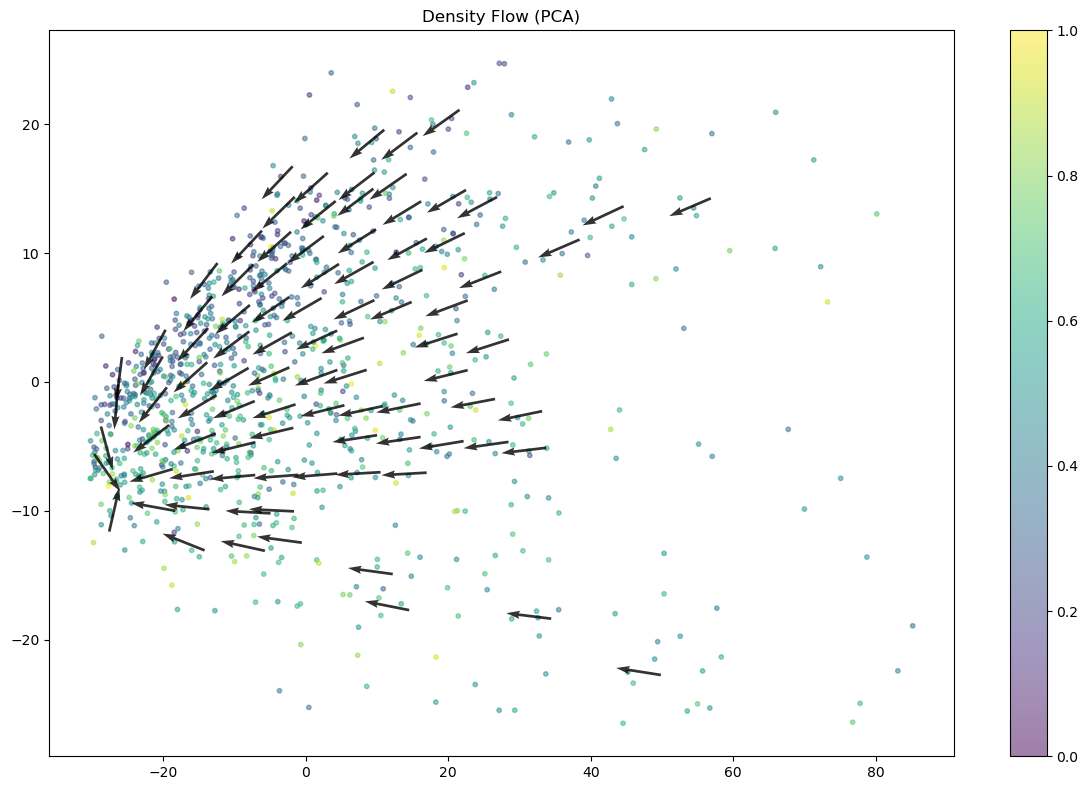

grid_X shape: (92, 2)
grid_V norm stats: 1.3080347230235858 28.42535916836865 56.99714427547027


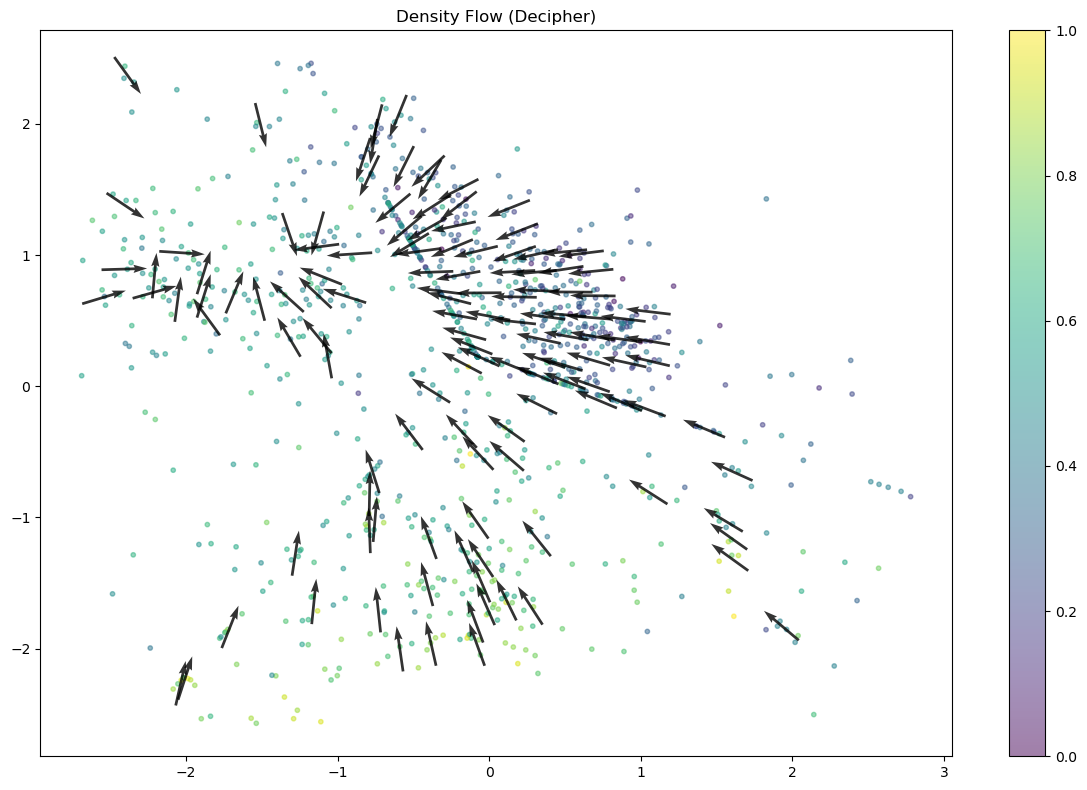

grid_X shape: (130, 2)
grid_V norm stats: 0.08588098295980934 1.2039574670515392 3.3890100227768136


In [69]:
from sklearn.neighbors import KernelDensity
import matplotlib.pyplot as plt
%matplotlib inline

kde = KernelDensity(bandwidth=0.5).fit(X_rna_z)
log_dens = kde.score_samples(X_rna_z)

# local gradient via neighbors
nn = NearestNeighbors(n_neighbors=20).fit(X_rna_z)
idx = nn.kneighbors(X_rna_z, return_distance=False)

V = np.zeros((N, 2))

for i in range(N):
    nbrs = idx[i]
    delta = X_pca[nbrs] - X_pca[i]
    dens_diff = log_dens[nbrs] - log_dens[i]

    score = -(dens_diff)

    # subtract mean to avoid flat regions
    score = score - score.mean()
    
    # softmax → always nonzero weights
    w = np.exp(score / (np.std(score) + 1e-8))
    w /= (w.sum() + 1e-8)
    
    V[i] = w @ delta

# Assuming you've calculated V (the density gradient)
plot_velocity_field(X_pca, V, color=ps, title="Density Flow (PCA)", 
                    grid_size=20, scale=20)

V_dec = np.zeros((N, 2))

for i in range(N):
    nbrs = idx[i]   # same neighbor graph (RNA space)

    delta = V_vis[nbrs] - V_vis[i]   # now in decipher space
    dens_diff = log_dens[nbrs] - log_dens[i]

    score = -(dens_diff)

    # subtract mean to avoid flat regions
    score = score - score.mean()
    
    # softmax → always nonzero weights
    w = np.exp(score / (np.std(score) + 1e-8))
    w /= (w.sum() + 1e-8)
    
    V_dec[i] = w @ delta

plot_velocity_field(V_vis, V_dec, color=ps, title="Density Flow (Decipher)",
                    grid_size=30, scale=20)

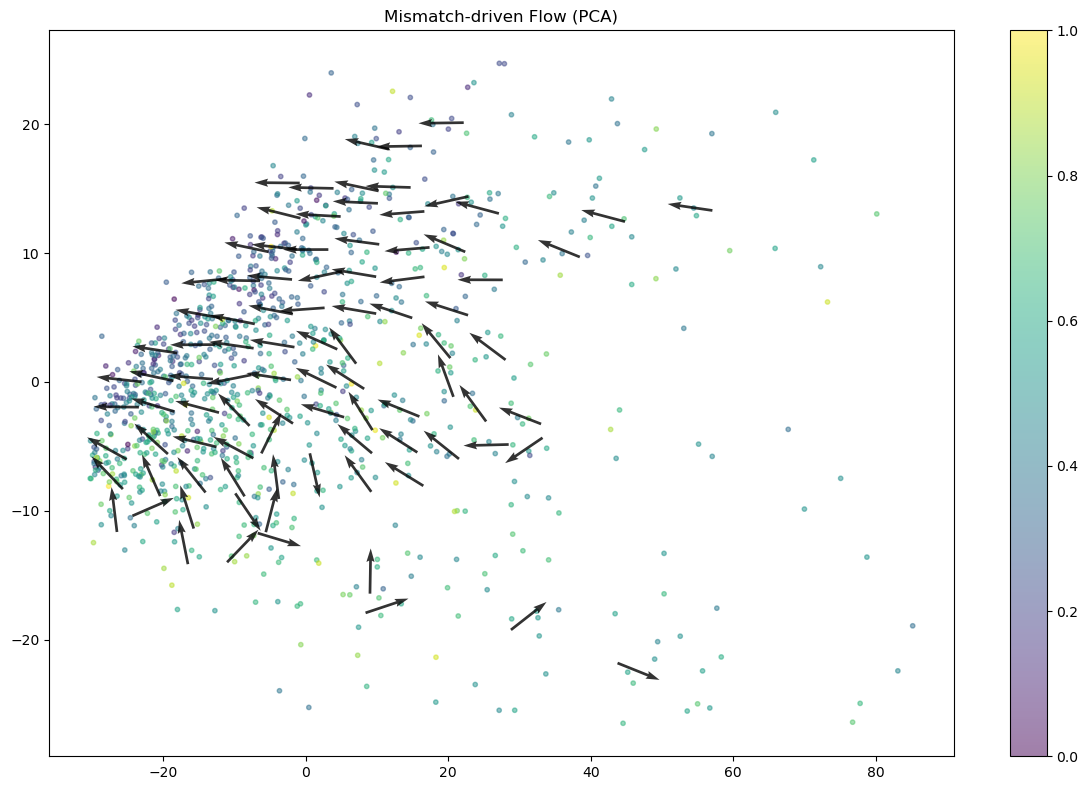

grid_X shape: (92, 2)
grid_V norm stats: 0.27143898574242875 0.8585535711935706 0.9960143444175162


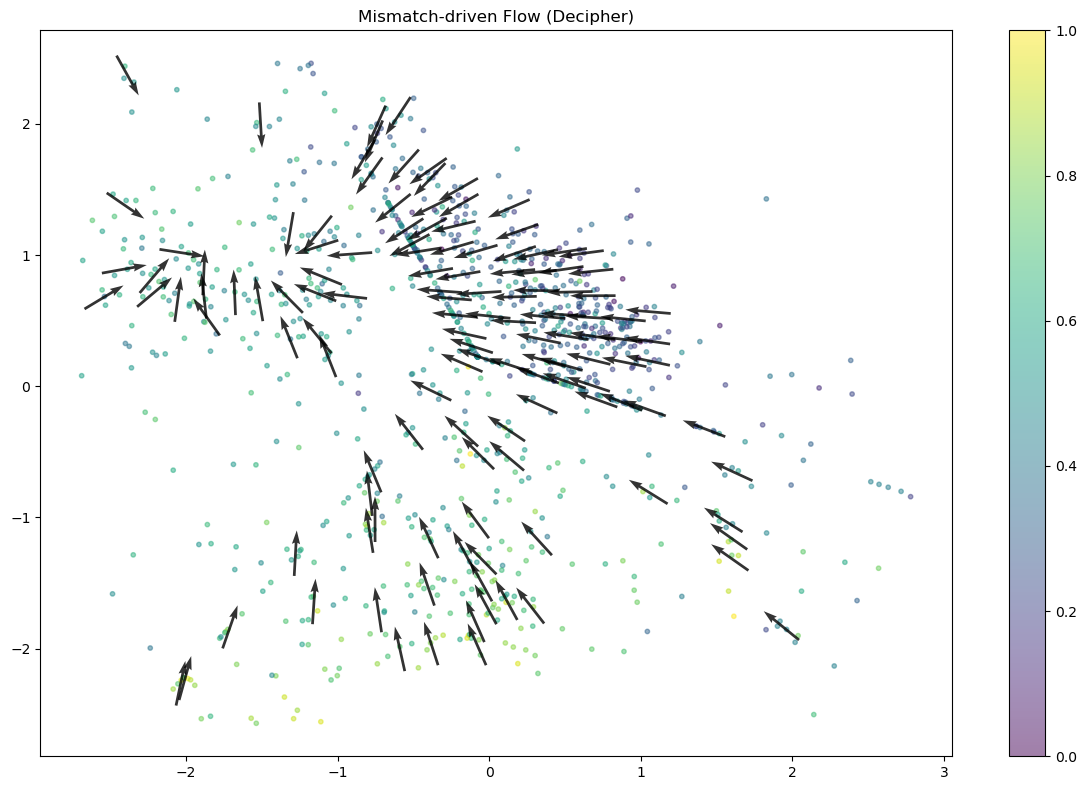

grid_X shape: (130, 2)
grid_V norm stats: 0.31395045203309213 0.995527505628926 0.9999983079814673


In [70]:
# mismatch per gene per cell
diff = X_rna_z - X_atac_z   # (N, G)

nn = NearestNeighbors(n_neighbors=20).fit(X_rna_z)
idx = nn.kneighbors(X_rna_z, return_distance=False)

V = np.zeros((N, 2))

for i in range(N):
    nbrs = idx[i]

    # --- FIX 1: use smooth mismatch signal (not scalar differences) ---
    mismatch_i = np.linalg.norm(diff[i])
    mismatch_n = np.linalg.norm(diff[nbrs], axis=1)

    # convert to soft preference (stable, non-sparse)
    score = mismatch_i - mismatch_n

    # --- FIX 2: softmax instead of hard clip (CRITICAL) ---
    score = score - score.max()
    w = np.exp(score / (np.std(score) + 1e-8))
    w = w / (w.sum() + 1e-8)

    # --- FIX 3: displacement in decipher space ---
    V[i] = w @ (V_vis[nbrs] - V_vis[i])

# normalize velocities (direction only, stable magnitude control)
V_norm = V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-8)

plot_velocity_field(
    X_pca,
    V_norm,
    color=ps,
    title="Mismatch-driven Flow (PCA)",
    grid_size=20,
    scale=1  # IMPORTANT: since V_norm is unit-normalized
)

plot_velocity_field(
    V_vis,
    V_norm,
    color=ps,
    title="Mismatch-driven Flow (Decipher)",
    grid_size=30,
    scale=1
)

## Local PCA geometry

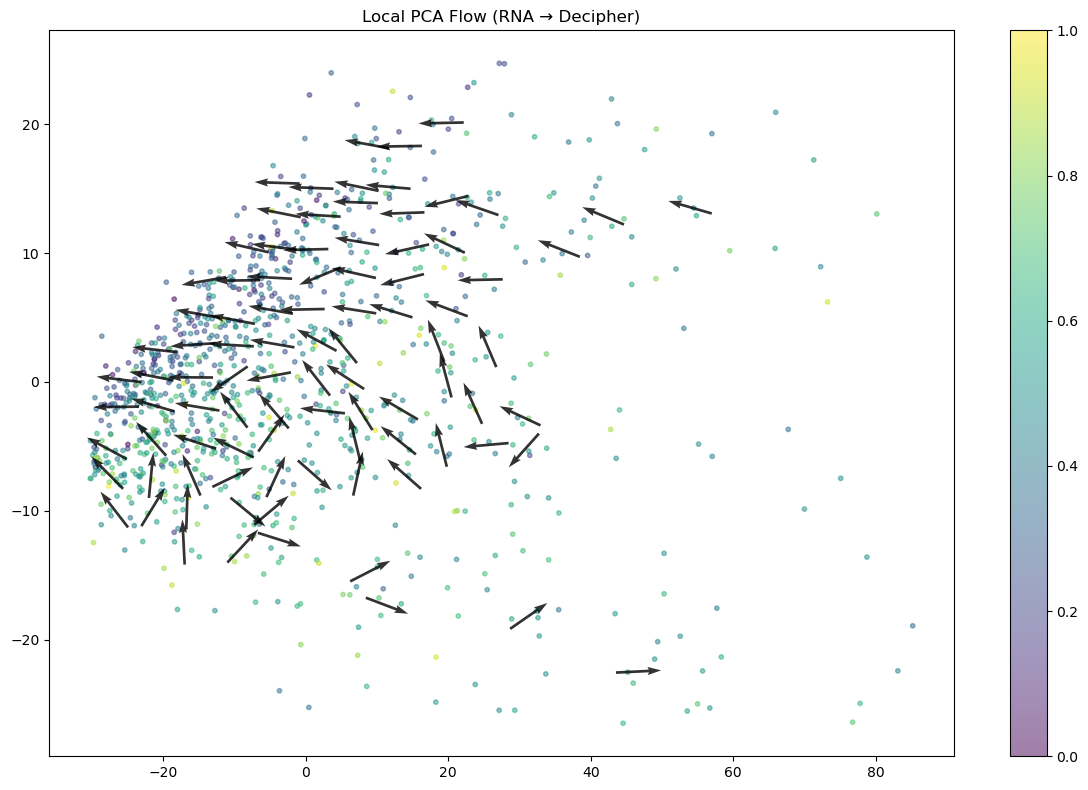

grid_X shape: (92, 2)
grid_V norm stats: 0.07337736923442688 0.8152797937318739 0.9989960693090292


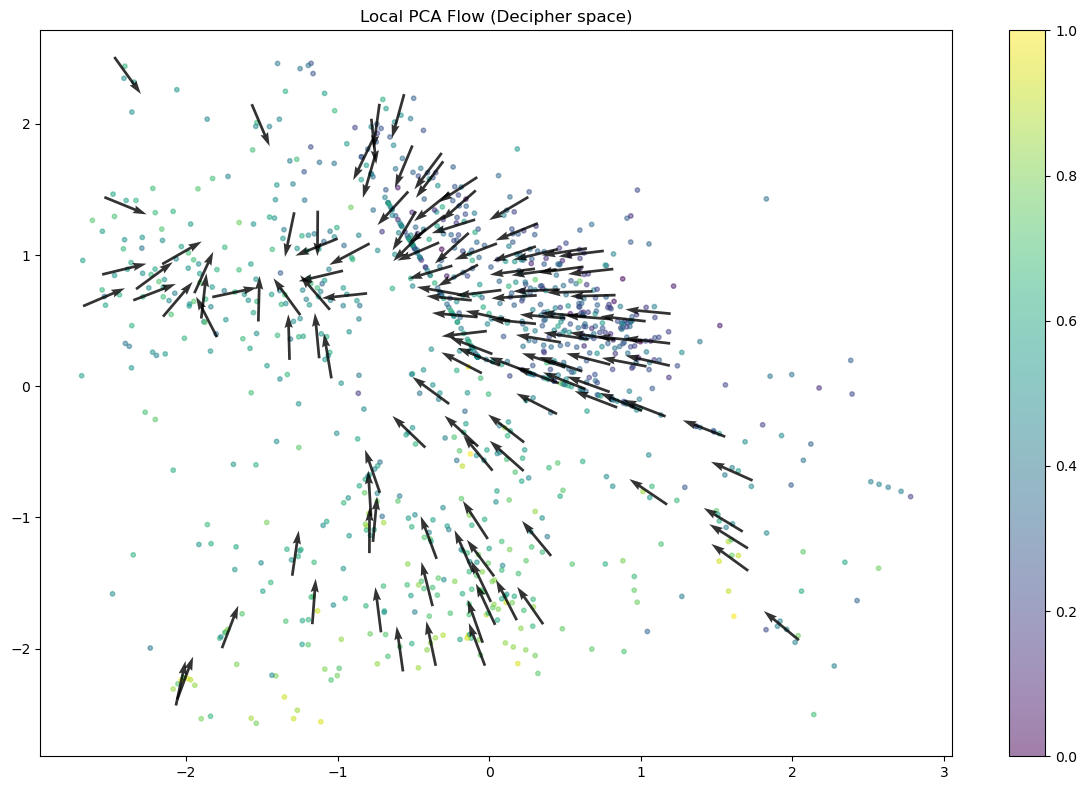

grid_X shape: (130, 2)
grid_V norm stats: 0.2674275888116167 0.9953976492380006 0.9999674062953221


In [71]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

nn = NearestNeighbors(n_neighbors=30).fit(X_rna_z)
idx = nn.kneighbors(X_rna_z, return_distance=False)

V = np.zeros((N, 2))

for i in range(N):
    nbrs = idx[i]
    X_local = X_rna_z[nbrs]

    # --- local PCA via SVD (your original idea, kept intact) ---
    Xc = X_local - X_local.mean(axis=0)

    # skip degenerate neighborhoods
    if np.linalg.norm(Xc) < 1e-8:
        continue

    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    pc1 = Vt[0]
    pc1 = pc1 / (np.linalg.norm(pc1) + 1e-8)

    # --- project neighbors onto local direction ---
    delta = X_local - X_rna_z[i]
    proj = delta @ pc1

    # --- FIX: soft weights instead of hard clip ---
    w = np.exp(proj / (np.std(proj) + 1e-8))
    w = w / (w.sum() + 1e-8)

    # --- map into decipher space ---
    V[i] = w @ (V_vis[nbrs] - V_vis[i])

# normalize velocity
V_norm = V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-8)

plot_velocity_field(
    X_pca,
    V_norm,
    color=ps,
    title="Local PCA Flow (RNA → Decipher)",
    grid_size=20,
    scale=1
)

plot_velocity_field(
    V_vis,
    V_norm,
    color=ps,
    title="Local PCA Flow (Decipher space)",
    grid_size=30,
    scale=1
)

## Graph diffusion direction

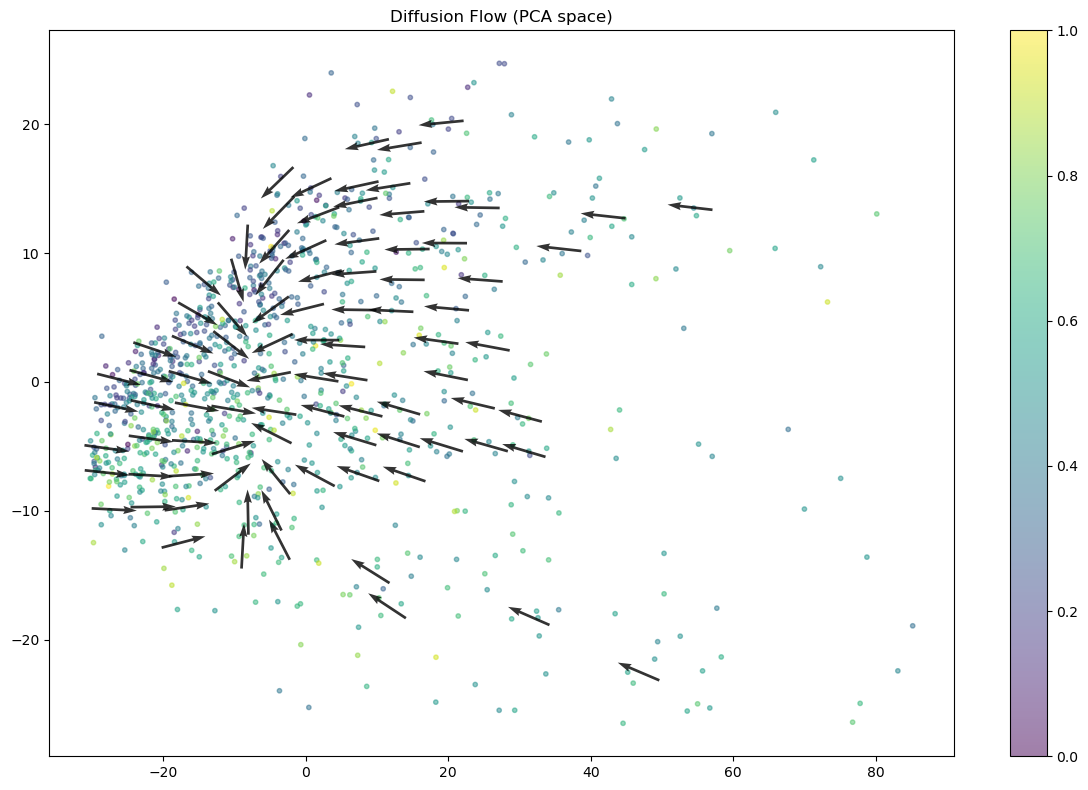

grid_X shape: (92, 2)
grid_V norm stats: 0.037518416 0.24414432 1.0269395


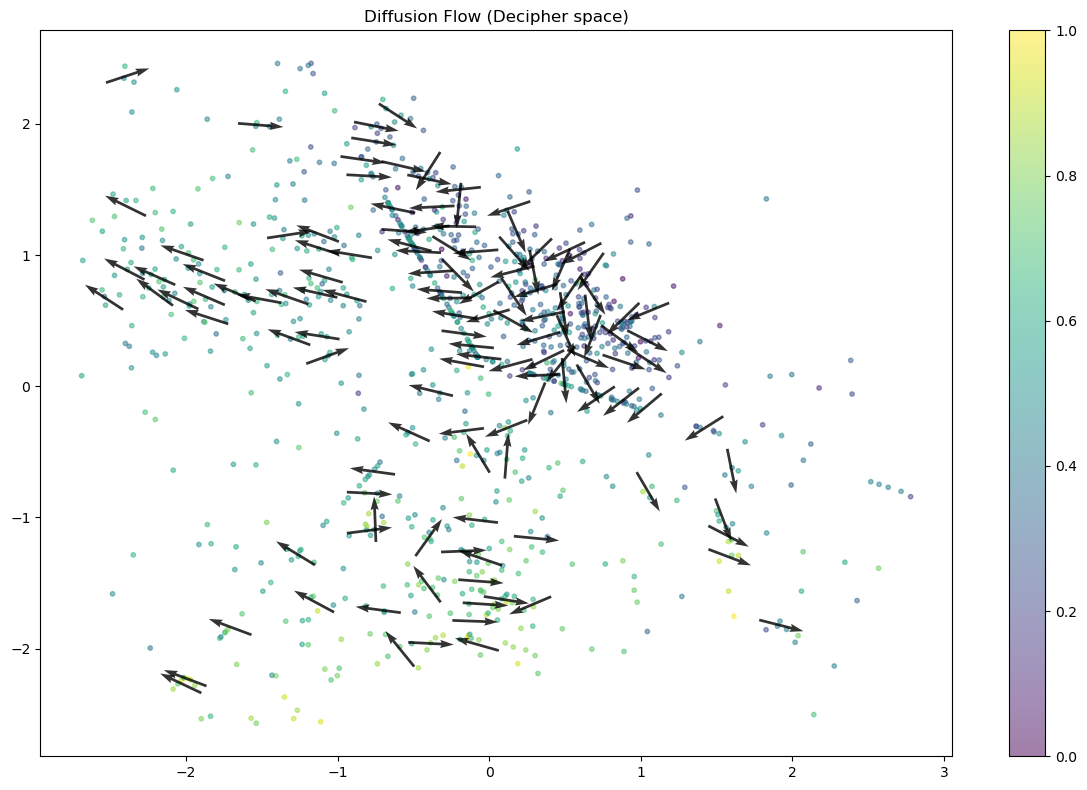

grid_X shape: (130, 2)
grid_V norm stats: 0.025621349 0.13804044 1.0570036


In [72]:
from sklearn.metrics.pairwise import rbf_kernel
import numpy as np
from sklearn.neighbors import NearestNeighbors

# --- FIX 1: adaptive gamma (important for stability) ---
dists = NearestNeighbors(n_neighbors=15).fit(X_rna_z).kneighbors(X_rna_z, return_distance=True)[0]
sigma = np.median(dists)
gamma = 1.0 / (2 * sigma**2 + 1e-8)

# --- diffusion kernel ---
K = rbf_kernel(X_rna_z, gamma=gamma)

# row-normalize (Markov transition matrix)
K = K / (K.sum(axis=1, keepdims=True) + 1e-8)

# --- diffusion step ---
X_diff = K @ X_rna_z

# --- velocity in gene space ---
V_gene = X_diff - X_rna_z

V_2d = (X_diff - X_rna_z) @ pca_vis.components_.T[:, :2]

nn = NearestNeighbors(n_neighbors=20).fit(X_pca)
idx = nn.kneighbors(X_pca, return_distance=False)

V_2d_smooth = np.array([
    V_2d[idx[i]].mean(axis=0)
    for i in range(N)
])

V_norm = V_2d_smooth / (np.percentile(np.linalg.norm(V_2d_smooth, axis=1), 95) + 1e-8)

plot_velocity_field(
    X_pca,
    V_norm,
    color=ps,
    title="Diffusion Flow (PCA space)",
    grid_size=20,
    scale=1
)

plot_velocity_field(
    V_vis,
    V_norm,
    color=ps,
    title="Diffusion Flow (Decipher space)",
    grid_size=30,
    scale=1
)


## TF activity driven

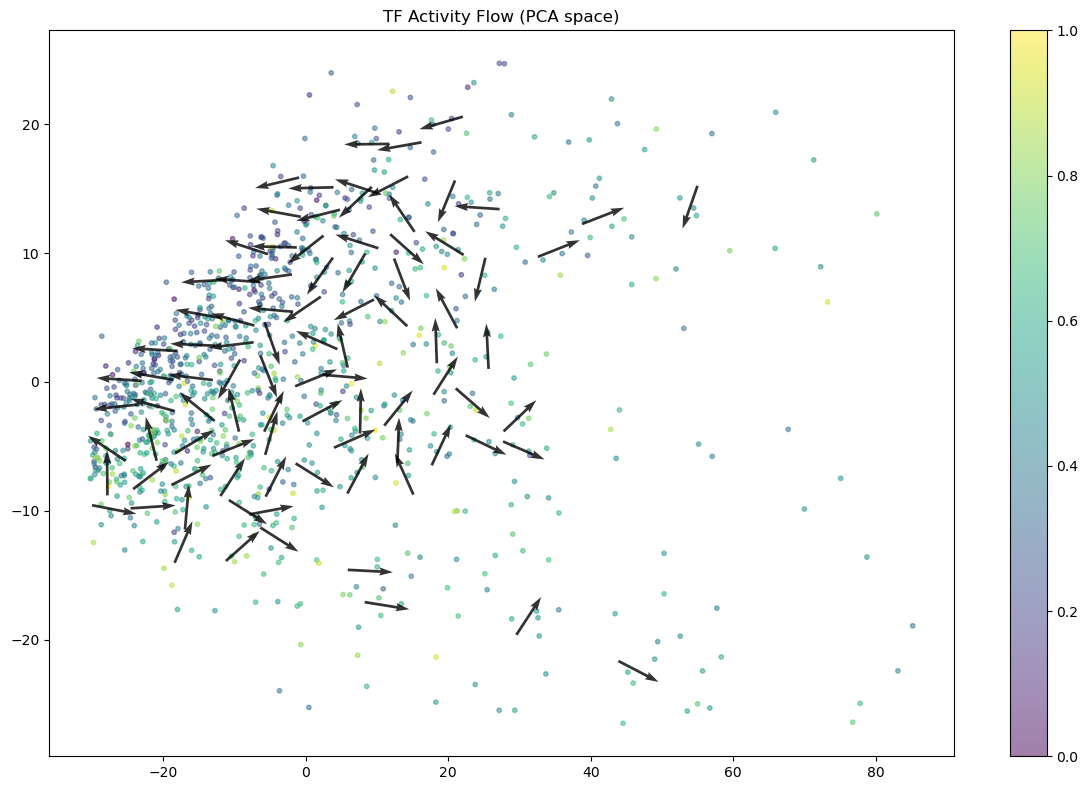

grid_X shape: (92, 2)
grid_V norm stats: 0.05371997358395074 0.507097378559513 0.992653989372837


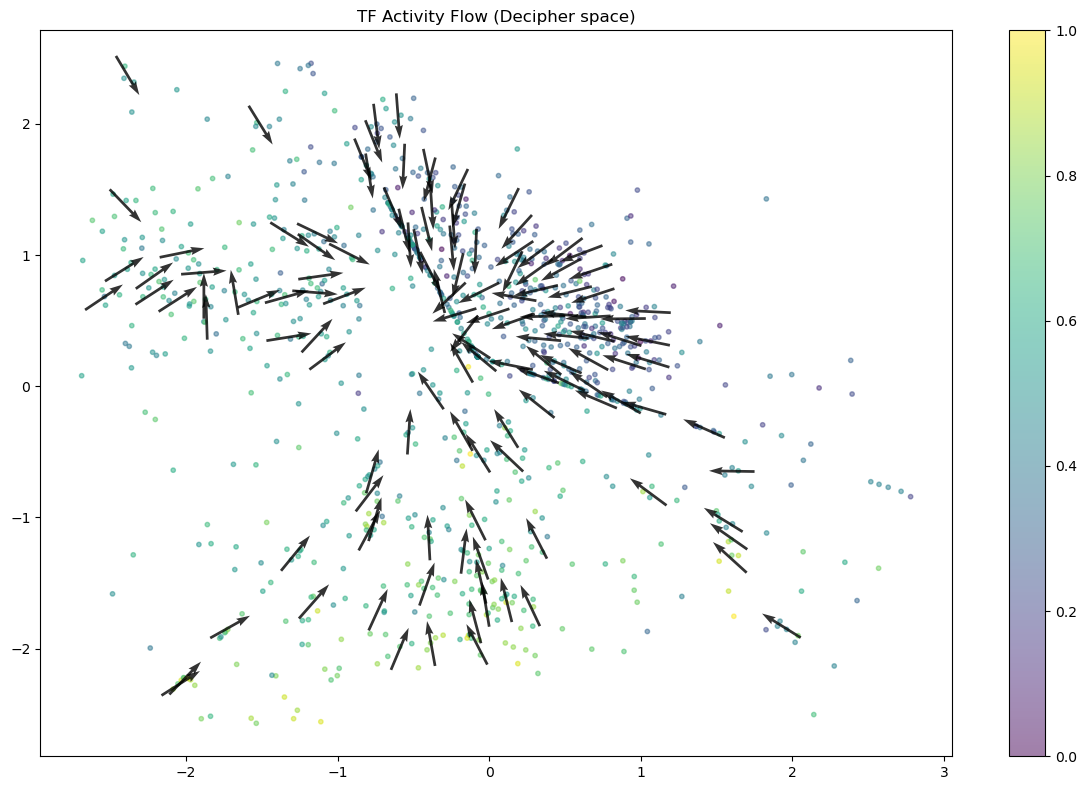

grid_X shape: (130, 2)
grid_V norm stats: 0.03559724524621075 0.9377428146367222 0.9988201206034005


In [73]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

nn = NearestNeighbors(n_neighbors=20).fit(X_TF_arr)
idx = nn.kneighbors(X_TF_arr, return_distance=False)

V = np.zeros((N, 2))

for i in range(N):
    nbrs = idx[i]

    # --- FIX 1: TF difference structure ---
    delta_tf = X_TF_arr[nbrs] - X_TF_arr[i]

    # use squared magnitude (more stable than raw L2)
    mag = np.linalg.norm(delta_tf, axis=1) ** 2

    # --- FIX 2: soft probabilistic weights (instead of raw normalization) ---
    mag = mag - mag.max()
    w = np.exp(mag / (np.std(mag) + 1e-8))
    w = w / (w.sum() + 1e-8)

    # --- FIX 3: map into decipher space ---
    V[i] = w @ (V_vis[nbrs] - V_vis[i])

# normalize for visualization stability
V_norm = V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-8)

plot_velocity_field(
    X_pca,
    V_norm,
    color=ps,
    title="TF Activity Flow (PCA space)",
    grid_size=20,
    scale=1
)

plot_velocity_field(
    V_vis,
    V_norm,
    color=ps,
    title="TF Activity Flow (Decipher space)",
    grid_size=30,
    scale=1
)

## Cell cycle / proliferation proxy

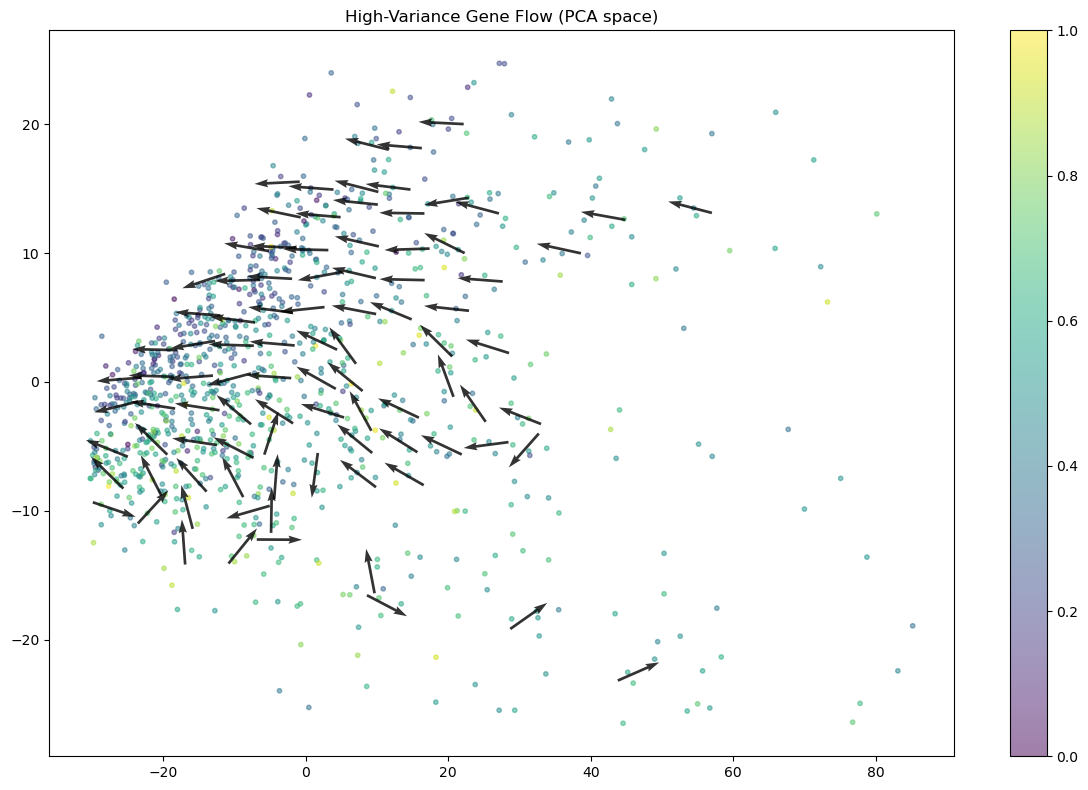

grid_X shape: (92, 2)
grid_V norm stats: 0.028724452064613614 0.8583558234526165 0.9961024202210904


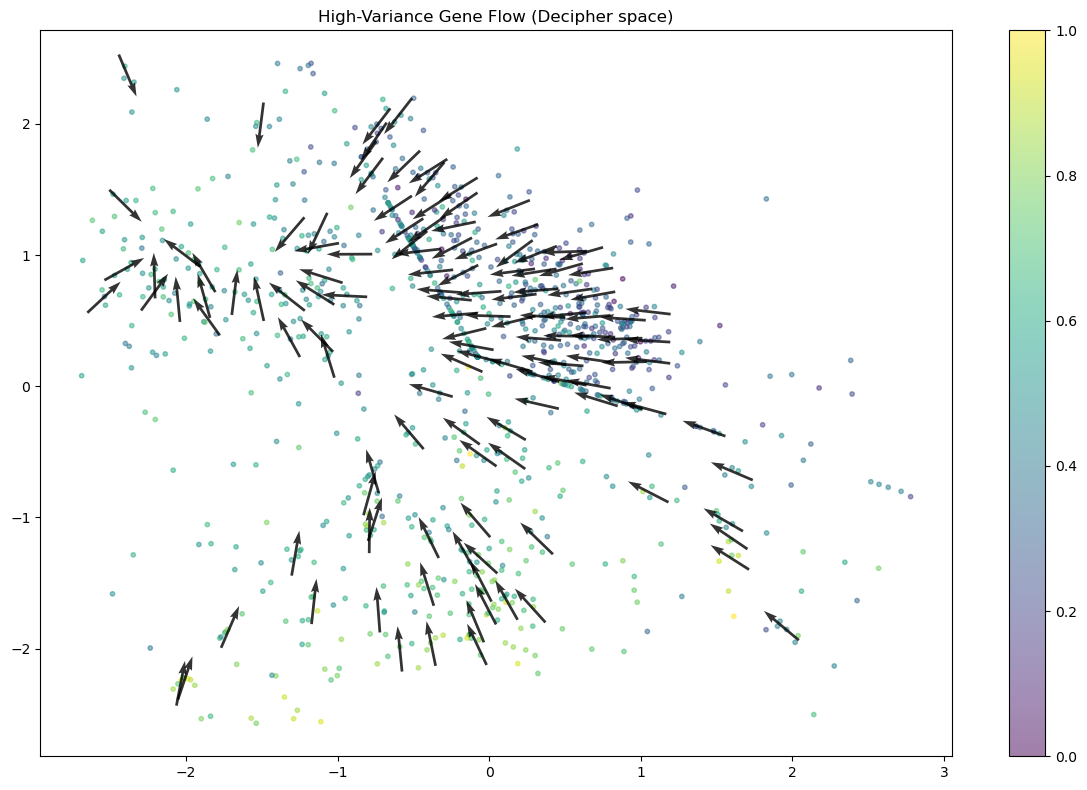

grid_X shape: (130, 2)
grid_V norm stats: 0.36407175984191725 0.9829780403734626 0.9999859509233542


In [74]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

# --- Step 1: high-variance gene signature ---
gene_var = np.var(X_rna_z, axis=0)
top_genes = np.argsort(-gene_var)[:200]

# --- Step 2: smooth per-cell activity score ---
score = X_rna_z[:, top_genes].mean(axis=1)

nn = NearestNeighbors(n_neighbors=20).fit(X_rna_z)
idx = nn.kneighbors(X_rna_z, return_distance=False)

V = np.zeros((N, 2))

for i in range(N):
    nbrs = idx[i]

    # --- FIX 1: smooth directional signal ---
    s_diff = score[nbrs] - score[i]

    # convert to probabilistic weights (not hard threshold)
    s_diff = s_diff - s_diff.max()
    w = np.exp(s_diff / (np.std(s_diff) + 1e-8))
    w = w / (w.sum() + 1e-8)

    # --- FIX 2: velocity in decipher space ---
    V[i] = w @ (V_vis[nbrs] - V_vis[i])

# --- normalization for stable visualization ---
V_norm = V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-8)

plot_velocity_field(
    X_pca,
    V_norm,
    color=ps,
    title="High-Variance Gene Flow (PCA space)",
    grid_size=20,
    scale=1
)

plot_velocity_field(
    V_vis,
    V_norm,
    color=ps,
    title="High-Variance Gene Flow (Decipher space)",
    grid_size=30,
    scale=1
)

## Consensus vector field

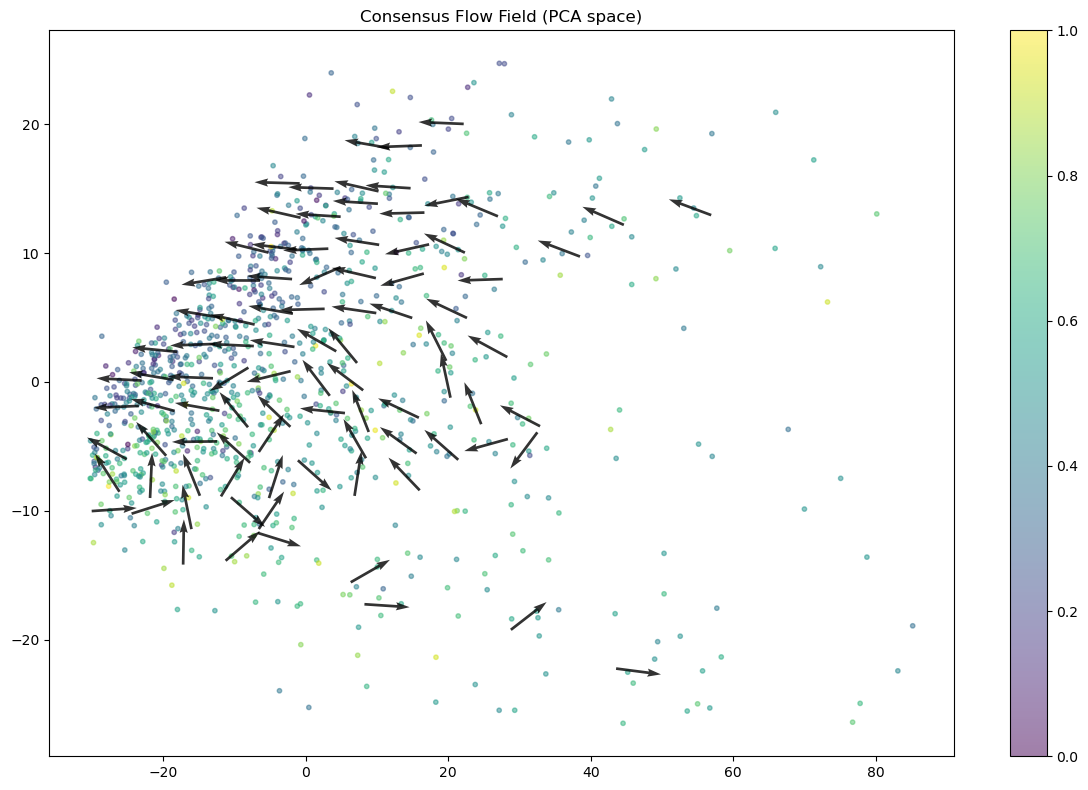

grid_X shape: (92, 2)
grid_V norm stats: 0.07711333898734878 0.81393206538822 0.9942336352098187


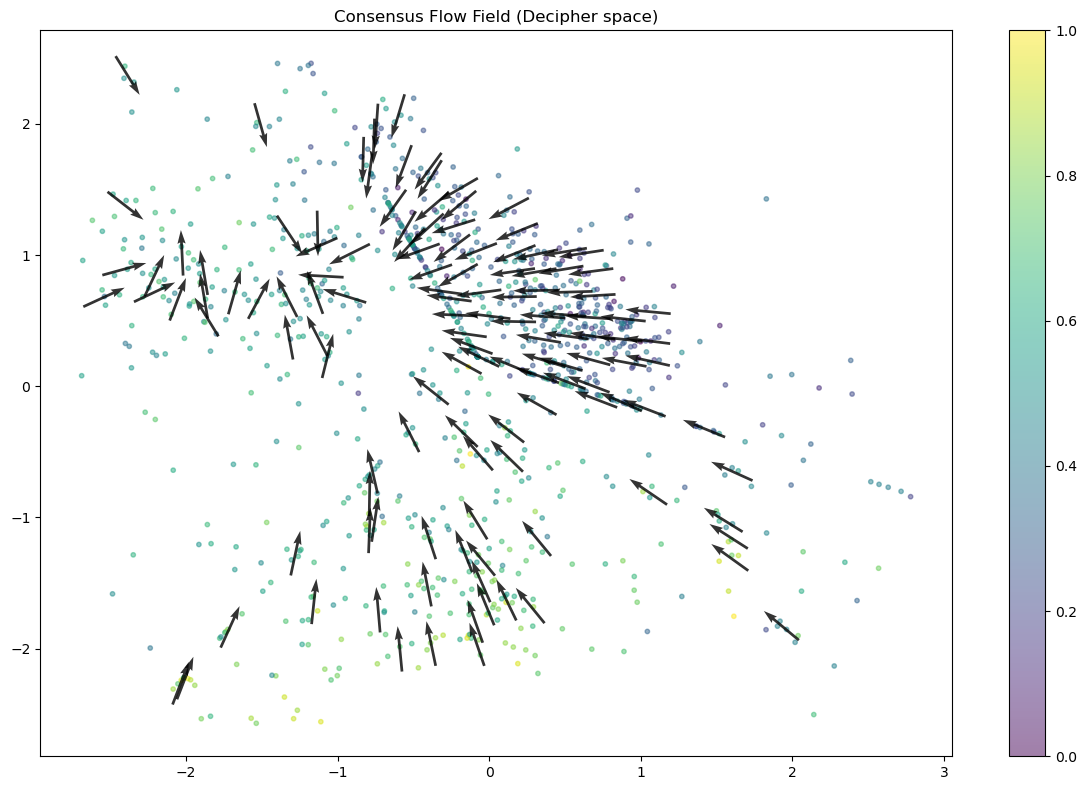

grid_X shape: (130, 2)
grid_V norm stats: 0.18637290050064742 0.994419364047967 0.9999709448533525


In [76]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

nn = NearestNeighbors(n_neighbors=30).fit(X_rna_z)
idx = nn.kneighbors(X_rna_z, return_distance=False)

V = np.zeros((N, 2))

for i in range(N):
    nbrs = idx[i]

    # -------------------------------
    # 1. GEOMETRIC CONSENSUS (diffusion)
    # -------------------------------
    delta_geo = V_vis[nbrs] - V_vis[i]
    geo_score = -np.linalg.norm(delta_geo, axis=1)

    # -------------------------------
    # 2. ATAC-RNA CONSISTENCY
    # -------------------------------
    diff = X_rna_z - X_atac_z
    atac_score = -(np.linalg.norm(diff[nbrs], axis=1))

    # -------------------------------
    # 3. TF ALIGNMENT (local variation)
    # -------------------------------
    tf_delta = X_TF_arr[nbrs] - X_TF_arr[i]
    tf_score = -np.linalg.norm(tf_delta, axis=1)

    # -------------------------------
    # 4. DENSITY FLOW (geometry pressure proxy)
    # -------------------------------
    local = X_rna_z[nbrs]
    density_score = -np.linalg.norm(local - X_rna_z[i], axis=1)

    # -------------------------------
    # COMBINE SCORES (CRITICAL STEP)
    # -------------------------------
    score = (
        0.4 * geo_score +
        0.3 * atac_score +
        0.2 * tf_score +
        0.1 * density_score
    )

    # -------------------------------
    # STABLE MARKOV NORMALIZATION
    # -------------------------------
    score = score - score.max()
    w = np.exp(score / (np.std(score) + 1e-8))
    w = w / (w.sum() + 1e-8)

    # -------------------------------
    # CONSENSUS VELOCITY IN DECIPHER SPACE
    # -------------------------------
    V[i] = w @ (V_vis[nbrs] - V_vis[i])

# normalize
V_norm = V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-8)

plot_velocity_field(
    X_pca,
    V_norm,
    color=ps,
    title="Consensus Flow Field (PCA space)",
    grid_size=20,
    scale=1
)

plot_velocity_field(
    V_vis,
    V_norm,
    color=ps,
    title="Consensus Flow Field (Decipher space)",
    grid_size=30,
    scale=1
)

## New Model

In [84]:
class CausalRegulatoryFlow(nn.Module):
    def __init__(self, G, T, K, M):
        super().__init__()

        self.U = nn.Parameter(0.01 * torch.randn(G, K))
        self.V = nn.Parameter(0.01 * torch.randn(T, K))
        self.register_buffer("M_mask", torch.tensor((M > 0).astype("float32")))

        self.gamma = nn.Parameter(torch.ones(G) * 0.05)

        self.potential = nn.Sequential(
            nn.Linear(G + T, 128),
            nn.GELU(),
            nn.Linear(128, 1)
        )

    def grn_matrix(self):
        return (self.U @ self.V.T) * self.M_mask

    def grn_signal(self, X_TF):
        A = self.grn_matrix()
        return X_TF @ A.T

    def forward(self, X_TF, X_genes):
        production = self.grn_signal(X_TF)
        decay = X_genes * torch.abs(self.gamma)
        net = production - decay

        h = torch.cat([net, X_TF], dim=1)
        return self.potential(h), net

In [98]:
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

G_dim = X.shape[1]
T_dim = X_TF.shape[1]
K_rank = 20

model = CausalRegulatoryFlow(G_dim, T_dim, K_rank, M).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)

# -----------------------
# DATA
# -----------------------
X_rna_t = torch.tensor(X, dtype=torch.float32, device=device)
X_atac_t = torch.tensor(X_atac_pred, dtype=torch.float32, device=device)
X_TF_t   = torch.tensor(X_TF, dtype=torch.float32, device=device)

N = X.shape[0]
batch_size = 512
K = 32

neg_idx = torch.randint(0, N, (N, K), device=device)

scaler = torch.cuda.amp.GradScaler()

# -----------------------
# LOSSES
# -----------------------

def causal_ordering_loss(pot_full, batch_idx, neg_idx):
    """
    pot_full: [N]
    """

    pot_b = pot_full[batch_idx]                      # [B]
    pot_n = pot_full[neg_idx[batch_idx]]             # [B, K]

    # ranking signal is purely in potential space
    diff = pot_b.unsqueeze(1) - pot_n                # [B, K]

    # hinge-style ordering loss
    return F.relu(diff).mean()


def geometric_consistency_loss(net, x_rna, x_atac):
    """
    Enforces alignment between predicted flow and observed displacement.
    """

    delta = x_atac - x_rna

    delta = F.normalize(delta, dim=1)
    net = F.normalize(net, dim=1)

    # orthogonal penalty (better than cosine-only)
    proj = (net * delta).sum(dim=1, keepdim=True) * delta
    orth = net - proj

    return orth.pow(2).mean()


def grn_sparsity(U, V):
    return U.abs().mean() + V.abs().mean()


def grn_stability(net):
    return net.pow(2).mean()

# -----------------------
# TRAIN LOOP
# -----------------------

W = dict(order=1.0, geom=0.1, sparse=0.05, stability=0.1)

for epoch in range(50):

    model.train()
    total = 0.0

    perm = torch.randperm(N, device=device)

    # 🔥 compute full potentials ONCE per epoch step
    with torch.no_grad():
        full_pot, _ = model(X_TF_t, X_rna_t)
        full_pot = full_pot.squeeze()

    for i in range(0, N, batch_size):

        idx = perm[i:i+batch_size]

        x_rna = X_rna_t[idx]
        x_tf  = X_TF_t[idx]
        x_atac = X_atac_t[idx]

        opt.zero_grad()

        with torch.cuda.amp.autocast():

            # batch-only forward (for geometry + net)
            _, net = model(x_tf, x_rna)

            # causal ordering (NOW FIXED)
            l_order = causal_ordering_loss(
                full_pot,
                idx,
                neg_idx
            )

            # geometry loss still local (correct)
            l_geom = geometric_consistency_loss(net, x_rna, x_atac)

            l_sparse = grn_sparsity(model.U, model.V)
            l_stable = grn_stability(net)

            loss = (
                l_order +
                0.1 * l_geom +
                0.05 * l_sparse +
                0.1 * l_stable
            )

        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()

        total += loss.item()

    print(f"[{epoch:03d}] loss={total:.4f}")

[000] loss=27.3359
[001] loss=19.2634
[002] loss=14.6038
[003] loss=14.5673
[004] loss=13.3989
[005] loss=7.3588
[006] loss=5.7351
[007] loss=6.6769
[008] loss=5.2423
[009] loss=5.0476
[010] loss=3.7893
[011] loss=4.4596
[012] loss=3.7623
[013] loss=3.6328
[014] loss=3.8475
[015] loss=3.5937
[016] loss=3.2419
[017] loss=3.1124
[018] loss=3.6656
[019] loss=3.5206
[020] loss=4.3581
[021] loss=3.5472
[022] loss=3.0519
[023] loss=3.6686
[024] loss=3.8522
[025] loss=5.0970
[026] loss=4.2310
[027] loss=3.6505
[028] loss=3.5619
[029] loss=2.8964
[030] loss=3.1439
[031] loss=3.8693
[032] loss=3.5569
[033] loss=3.1694
[034] loss=3.3854
[035] loss=3.8272
[036] loss=4.2174
[037] loss=4.1491
[038] loss=3.7482
[039] loss=4.2507
[040] loss=3.7993
[041] loss=2.9108
[042] loss=2.8535
[043] loss=3.5521
[044] loss=3.1606
[045] loss=3.4201
[046] loss=3.7808
[047] loss=3.1983
[048] loss=4.4101
[049] loss=3.3082


In [89]:
with torch.no_grad():
    pot = model.potential(torch.cat([net_signal, X_TF_t], dim=1)).squeeze()

# approximate velocity = gradient of potential
V_z = torch.autograd.grad(
    outputs=pot.sum(),
    inputs=X_z_t,
    retain_graph=False,
    create_graph=False
)[0].cpu().numpy()

RuntimeError: Sizes of tensors must match except in dimension 1. Expected size 512 but got size 1035 for tensor number 1 in the list.

In [114]:
def compute_velocity(potential, X, k=20):
    from sklearn.neighbors import NearestNeighbors
    import numpy as np

    N, D = X.shape

    nn = NearestNeighbors(n_neighbors=k).fit(X)
    idx = nn.kneighbors(X, return_distance=False)

    V = np.zeros((N, D))

    for i in range(N):

        nbrs = idx[i]

        dp = potential[nbrs] - potential[i]
        dx = X[nbrs] - X[i]

        # 🔥 FIX 1: use signed weights (NO softmax, NO tanh saturation)
        w = dp / (np.linalg.norm(dp) + 1e-8)

        v = w @ dx

        # 🔥 FIX 2: DO NOT normalize per-point
        # (this is what destroyed your anisotropy)

        V[i] = v

    # 🔥 FIX 3: global normalization only (optional)
    scale = np.std(V)
    V = V / (scale + 1e-8)

    return V

In [106]:
def project_velocity(V, X_from, X_to, alpha=1.0):
    """
    Proper velocity transport using local linear map
    """

    from sklearn.linear_model import Ridge

    reg = Ridge(alpha=alpha).fit(X_from, X_to)
    J = reg.coef_  # (D_out, D_in)

    return V @ J.T

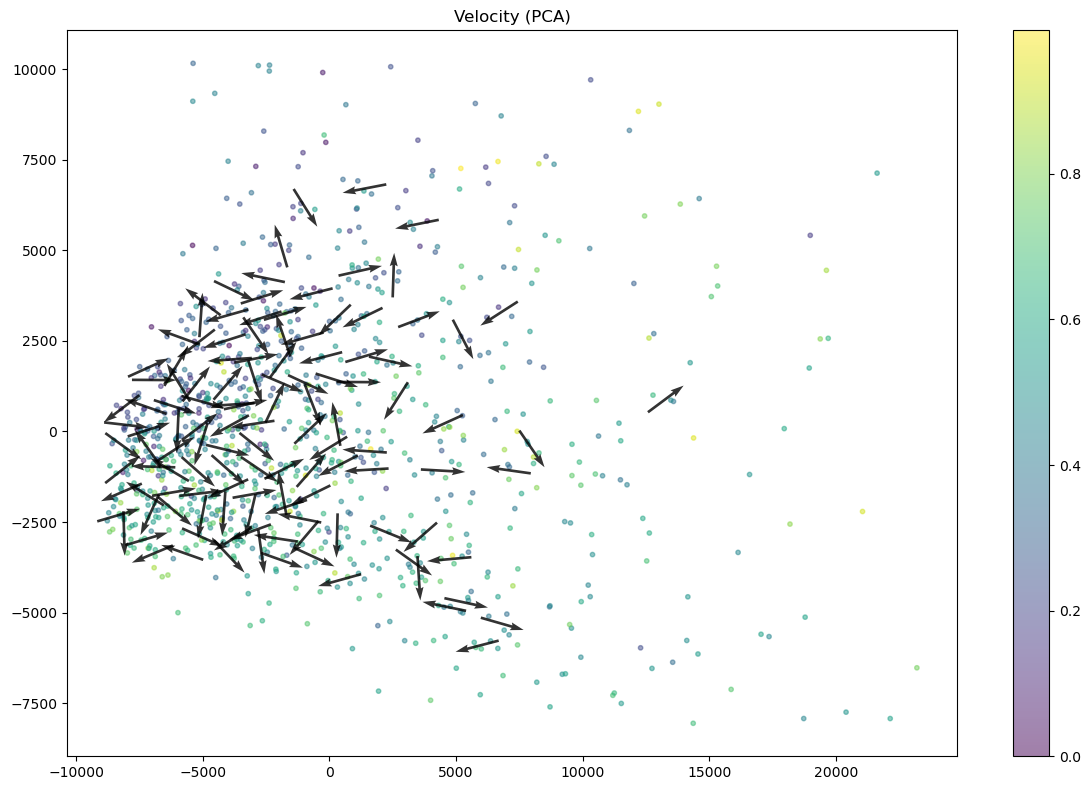

grid_X shape: (123, 2)
grid_V norm stats: 0.06049551737395113 0.350770803632948 0.9849821676402496


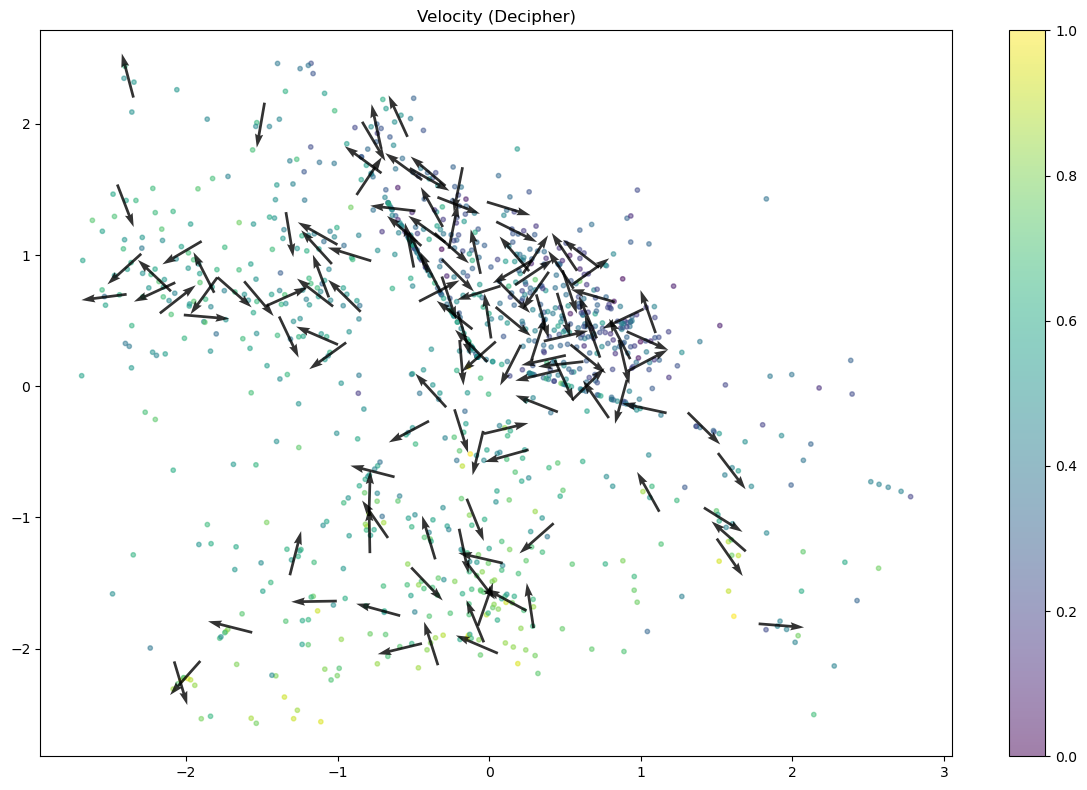

grid_X shape: (130, 2)
grid_V norm stats: 0.07312367074808927 0.4010122212035746 0.9951358954234568


In [115]:
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_rna_t.cpu().numpy())

# potential → gene velocity
with torch.no_grad():
    pot, _ = model(X_TF_t, X_rna_t)
    pot = pot.squeeze().cpu().numpy()

V_gene = compute_velocity(
    pot,
    X_atac_t.cpu().numpy(),
)

# -------------------------
# FIXED PROJECTION CHAIN
# -------------------------

# gene → Z
J_gene2z = Ridge(alpha=1.0).fit(X_rna_t.cpu().numpy(), Z_dec).coef_
V_z = project_velocity(V_gene, X_rna_t.cpu().numpy(), Z_dec)

# Z → Decipher
J_z2vis = Ridge(alpha=1.0).fit(Z_dec, V_vis).coef_
V_dec = project_velocity(V_z, Z_dec, V_vis)
# normalize
V_pca = V_gene @ pca.components_.T
V_pca /= (np.linalg.norm(V_pca, axis=1, keepdims=True) + 1e-8)

V_dec /= (np.linalg.norm(V_dec, axis=1, keepdims=True) + 1e-8)

# plots
plot_velocity_field(X_pca, V_pca, color=ps, title="Velocity (PCA)")
plot_velocity_field(V_vis, V_dec, color=ps, title="Velocity (Decipher)")

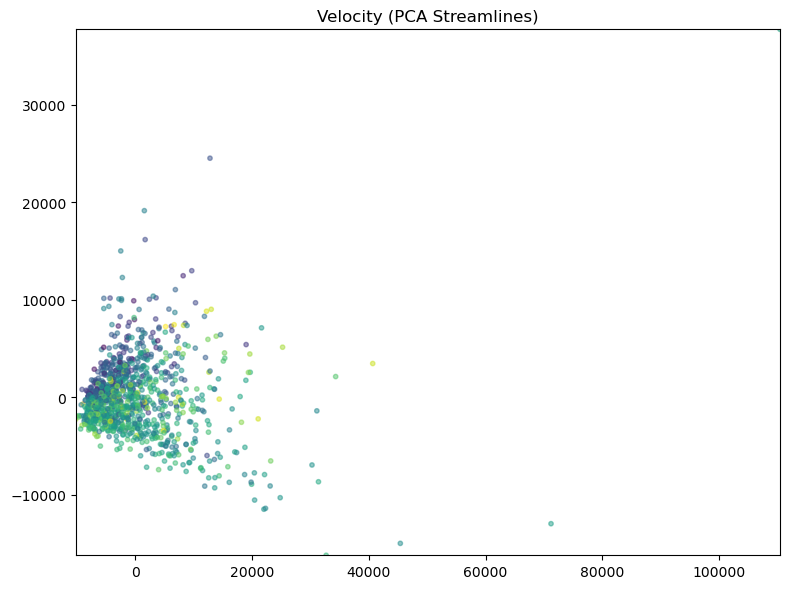

In [123]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_rna_t.cpu().numpy())

with torch.no_grad():
    pot, _ = model(X_TF_t, X_rna_t)
    pot = pot.squeeze().cpu().numpy()

V_gene = compute_velocity(
    pot,
    X_rna_t.cpu().numpy(),
    k=20
)
V_gene = V_gene / (np.std(V_gene) + 1e-8)

V_pca = V_gene @ pca.components_.T

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.ndimage import gaussian_filter

def streamplot_velocity(X_2d, V_2d, ps, title="Velocity Streamplot", grid_n=40):

    x_min, x_max = X_2d[:, 0].min(), X_2d[:, 0].max()
    y_min, y_max = X_2d[:, 1].min(), X_2d[:, 1].max()

    gx = np.linspace(x_min, x_max, grid_n)
    gy = np.linspace(y_min, y_max, grid_n)
    GX, GY = np.meshgrid(gx, gy)

    grid = np.stack([GX.ravel(), GY.ravel()], axis=1)

    nn = NearestNeighbors(radius=0.35).fit(X_2d)
    dists, idxs = nn.radius_neighbors(grid)

    U = np.zeros(len(grid))
    V = np.zeros(len(grid))
    mass = np.zeros(len(grid))

    for i, (d, idx) in enumerate(zip(dists, idxs)):
        if len(idx) > 5:
            w = np.exp(-np.array(d)**2 / (2 * 0.2**2))
            w = w / (w.sum() + 1e-8)

            U[i] = np.dot(w, V_2d[idx, 0])
            V[i] = np.dot(w, V_2d[idx, 1])
            mass[i] = len(idx)

    U = U.reshape(grid_n, grid_n)
    V = V.reshape(grid_n, grid_n)
    mass = mass.reshape(grid_n, grid_n)

    U = gaussian_filter(U, sigma=1.0)
    V = gaussian_filter(V, sigma=1.0)

    U[mass < 5] = np.nan
    V[mass < 5] = np.nan

    speed = np.linalg.norm(np.stack([U, V], axis=-1), axis=-1)
    speed = gaussian_filter(speed, sigma=0.6)

    fig, ax = plt.subplots(figsize=(8, 6))

    ax.scatter(X_2d[:, 0], X_2d[:, 1],
               c=ps, cmap='viridis', s=10, alpha=0.5)

    ax.streamplot(gx, gy, U, V,
                  color=speed,
                  cmap='plasma',
                  density=1.2,
                  linewidth=1.2,
                  arrowsize=1.5)

    ax.set_title(title)
    plt.tight_layout()
    plt.show()

streamplot_velocity(
    X_pca,
    V_pca,
    ps,
    title="Velocity (PCA Streamlines)"
)



In [113]:
V = V_gene  # your computed velocity

print(np.linalg.matrix_rank(V[:2000]))
print(np.mean(np.linalg.norm(V, axis=1)))
print(np.std(V, axis=0).mean())

1035
1.0000000025285856
0.008975059923967792


### PCA Visualization

In [ ]:
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
import numpy as np

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_z_t.cpu().numpy())

V_pca = V_z @ pca.components_.T

# smooth (important, avoids noisy arrows)
nn = NearestNeighbors(n_neighbors=30).fit(X_pca)
idx = nn.kneighbors(X_pca, return_distance=False)

V_pca_smooth = np.array([
    V_pca[idx[i]].mean(axis=0)
    for i in range(len(X_pca))
])

V_pca_smooth /= (np.linalg.norm(V_pca_smooth, axis=1, keepdims=True) + 1e-8)

plot_velocity_field(
    X_pca,
    V_pca_smooth,
    color=ps,
    title="Learned Potential Flow (PCA space)",
    grid_size=20,
    scale=1
)

### Decipher Visualization

In [ ]:
V_dec = V_z @ J_z2vis.T   # or ridge mapping you already used

nn = NearestNeighbors(n_neighbors=30).fit(V_vis)
idx = nn.kneighbors(V_vis, return_distance=False)

V_dec_smooth = np.array([
    V_dec[idx[i]].mean(axis=0)
    for i in range(len(V_vis))
])

V_dec_smooth /= (np.linalg.norm(V_dec_smooth, axis=1, keepdims=True) + 1e-8)

plot_velocity_field(
    V_vis,
    V_dec_smooth,
    color=ps,
    title="Learned Potential Flow (Decipher space)",
    grid_size=30,
    scale=1
)